## Wstęp do Uczenia Maszynowego

#### Laboratorium 04


### Zakres laboratorium

- walidacja krzyżowa i dobór hiperparametrów drzewa
- regresja liniowa
- regresja logistyczna
- interpretacja predykcji i współczynników modeli
- wprowadzenie do `Pipeline`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


In [2]:
# Dane wykorzystywane w sekcji o walidacji krzyżowej.
pima_cv = pd.read_csv("../lab02/pima.csv")
X_cv = pima_cv.drop(columns="Outcome")
y_cv = pima_cv["Outcome"]
X_cv_train, X_cv_test, y_cv_train, y_cv_test = train_test_split(
    X_cv, y_cv, test_size=0.3, random_state=123
)


### 1. Dokończenie: walidacja krzyżowa i dobór hiperparametrów

Walidacja krzyżowa pozwala ocenić model wielokrotnie na różnych fragmentach zbioru treningowego. Wyniki CV służą do porównywania modeli i doboru hiperparametrów; zbiór testowy zachowujemy na końcową, jednorazową ocenę wybranego modelu.

### Kroswalidacja (*ang. cross-validation*) a Leave-One-Out

W $k$-krotnej walidacji krzyżowej dane treningowe dzielimy na $k$ części. Model uczymy $k$ razy, za każdym razem walidując go na innej części; końcowy wynik jest średnią wyników z foldów. Leave-One-Out to szczególny przypadek z $k=n$: każdy fold ma jedną obserwację walidacyjną. Wykorzystuje niemal wszystkie dane do uczenia, ale wymaga $n$ dopasowań modelu.


![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)

Więcej: https://scikit-learn.org/stable/modules/cross_validation.html


---
##### *Zadanie 1*

Wymień zalety i wady kroswalidacji.


Zalety:

- pozwala wykorzystać wszystkie obserwacje ze zbioru treningowego zarówno do uczenia, jak i walidacji,
- daje bardziej stabilną ocenę niż pojedynczy podział danych.

Wady:

- wymaga wielokrotnego dopasowania modelu, więc wydłuża obliczenia,
- wyniki z foldów nie są niezależne, a modele są uczone na mniejszych zbiorach niż pełny zbiór treningowy.


---
##### *Zadanie 2*

Korzystając z przygotowanego wyżej zbioru treningowego `pima`, oszacuj jakość drzewa za pomocą 10-krotnej walidacji krzyżowej z miarą `accuracy`. Podaj średnią i odchylenie standardowe wyniku.


In [3]:
# Walidacja krzyżowa wyłącznie na zbiorze treningowym.
cv_10 = KFold(n_splits=10, shuffle=True, random_state=123)
cv_tree = tree.DecisionTreeClassifier(random_state=123)
scores_accuracy = cross_val_score(
    cv_tree, X_cv_train, y_cv_train, cv=cv_10, scoring="accuracy"
)


In [4]:
print("Wyniki 10-krotnej CV:", np.round(scores_accuracy, 3))
print(f"Średnia accuracy: {scores_accuracy.mean():.3f} ± {scores_accuracy.std():.3f}")


Wyniki 10-krotnej CV: [0.667 0.722 0.722 0.759 0.574 0.556 0.704 0.679 0.698 0.623]
Średnia accuracy: 0.670 ± 0.063


---
##### *Zadanie 3*

Na zbiorze treningowym wykonaj 100 powtórzeń 10-krotnej walidacji krzyżowej dla drzewa, używając miary `roc_auc`. Podaj średnią, odchylenie standardowe i narysuj rozkład wyników.


In [5]:
cv_repeated = RepeatedKFold(n_splits=10, n_repeats=100, random_state=123)
scores_auc = cross_val_score(
    tree.DecisionTreeClassifier(random_state=123),
    X_cv_train,
    y_cv_train,
    cv=cv_repeated,
    scoring="roc_auc",
)
print(f"Średnie ROC AUC: {scores_auc.mean():.3f} ± {scores_auc.std():.3f}")


Średnie ROC AUC: 0.650 ± 0.070


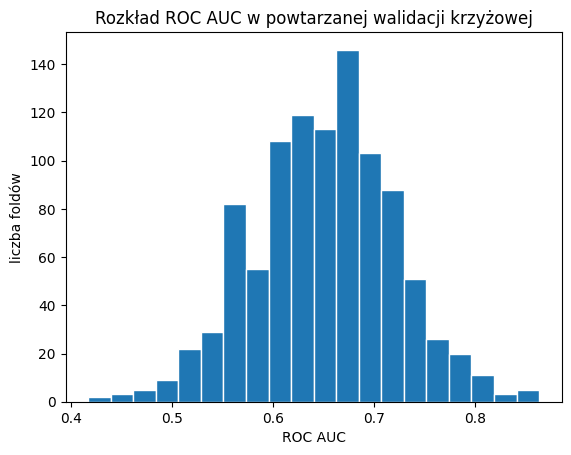

In [6]:
plt.hist(scores_auc, bins=20, edgecolor="white")
plt.xlabel("ROC AUC")
plt.ylabel("liczba foldów")
plt.title("Rozkład ROC AUC w powtarzanej walidacji krzyżowej")
plt.show()


---
##### *Zadanie 4*

Dla danych `pima` zbadaj zachowanie hiperparametru `max_leaf_nodes` drzewa klasyfikacyjnego w zakresie od 2 do 30. Na danych treningowych i w 5-krotnej CV oblicz `accuracy`, `precision` i `roc_auc`. Przygotuj wizualizację, wybierz wartość według `roc_auc` z CV, a następnie raz oceń wybrany model na zbiorze testowym.

> **Uwaga.** Hiperparametr wybieramy wyłącznie na podstawie wyniku walidacji krzyżowej. Zbiór testowy służy tylko do końcowej oceny wybranego modelu.


In [7]:
cv_5 = KFold(n_splits=5, shuffle=True, random_state=123)
results_cv = []
for max_leaves in range(2, 31):
    candidate = tree.DecisionTreeClassifier(
        max_leaf_nodes=max_leaves, random_state=123
    )
    results_cv.append({
        "max_leaf_nodes": max_leaves,
        "accuracy": cross_val_score(candidate, X_cv_train, y_cv_train, cv=cv_5,
                                      scoring="accuracy").mean(),
        "precision": cross_val_score(candidate, X_cv_train, y_cv_train, cv=cv_5,
                                       scoring="precision").mean(),
        "roc_auc": cross_val_score(candidate, X_cv_train, y_cv_train, cv=cv_5,
                                     scoring="roc_auc").mean(),
    })
results_cv = pd.DataFrame(results_cv)
results_cv.head()


,max_leaf_nodes,accuracy,precision,roc_auc
0,2,0.703808,0.698654,0.611142
1,3,0.724368,0.741630,0.696705
2,4,0.701938,0.683321,0.745893
3,5,0.752129,0.628889,0.768234
4,6,0.746573,0.639641,0.764251


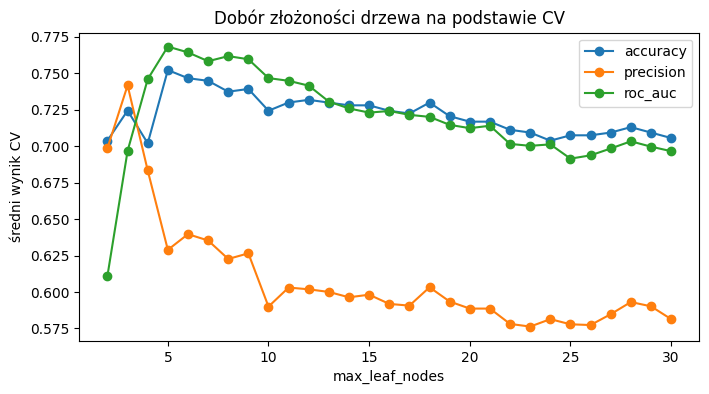

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for metric in ["accuracy", "precision", "roc_auc"]:
    ax.plot(results_cv["max_leaf_nodes"], results_cv[metric], marker="o", label=metric)
ax.set_xlabel("max_leaf_nodes")
ax.set_ylabel("średni wynik CV")
ax.set_title("Dobór złożoności drzewa na podstawie CV")
ax.legend()
plt.show()


In [9]:
best_max_leaves = results_cv.loc[results_cv["roc_auc"].idxmax(), "max_leaf_nodes"]
selected_tree = tree.DecisionTreeClassifier(
    max_leaf_nodes=best_max_leaves, random_state=123
)
selected_tree.fit(X_cv_train, y_cv_train)
y_cv_pred = selected_tree.predict(X_cv_test)
y_cv_score = selected_tree.predict_proba(X_cv_test)[:, 1]

print("Wybrane max_leaf_nodes:", best_max_leaves)
print("Accuracy na teście:", round(accuracy_score(y_cv_test, y_cv_pred), 3))
print("Precision na teście:", round(precision_score(y_cv_test, y_cv_pred), 3))
print("ROC AUC na teście:", round(roc_auc_score(y_cv_test, y_cv_score), 3))


Wybrane max_leaf_nodes: 5
Accuracy na teście: 0.753
Precision na teście: 0.657
ROC AUC na teście: 0.809


### 2. Model regresji liniowej

Równanie modelu (w postaci macierzowej)

$$Y = X \beta + \epsilon$$

Gdzie:

- $Y$ – wektor zmiennej objaśnianej (wymiar $n \times 1$)

- $X$ – macierz cech / zmiennych objaśniających (wymiar $n \times (p+1)$, gdzie pierwsza kolumna to same jedynki dla wyrazu wolnego)

- $\beta$ – wektor nieznanych parametrów / współczynników regresji (wymiar $(p+1) \times 1$)

- $\epsilon$ – wektor składników losowych / błędów (wymiar $n \times 1$)

Kluczowe założenia modelu

- wartość oczekiwana błędu: $E(\epsilon) = 0$

- homoskedastyczność (stała wariancja błędów): $Var(\epsilon \vert{} X) = \sigma^2 I$ (gdzie $I$ to macierz jednostkowa)

- brak współliniowości: macierz $X$ ma pełny rząd kolumnowy, co oznacza, że macierz $X^T X$ jest odwracalna


Współczynniki $\beta$ wyznacza się, minimalizując sumę kwadratów reszt ($RSS$):

$$RSS = \epsilon^T \epsilon = (Y - X\beta)^T (Y - X\beta) \to \min_{\beta}.$$

Rozwiązanie tego problemu prowadzi do wzoru analitycznego na estymator współczynników $\hat{\beta}$:$$\hat{\beta} = (X^T X)^{-1} X^T Y.$$

Przewidywane wartości zmiennej objaśnianej ($\hat{Y}$) dla nowych danych oblicza się jako:$$\hat{Y} = X\hat{\beta}.$$

In [10]:
# Wczytujemy zbiór danych do regresji liniowej
hills = pd.read_csv("hills.csv")

Zbiór danych dotyczący szkockich biegów górskich.
- dist – dystans trasy w milach,

- climb – suma przewyższenia w stópach,

- time – rekordowy czas (męski) w godzinach

> https://search.r-project.org/CRAN/refmans/DAAG/html/hills.html

-----
##### *Zadanie 5*

Dla danych `hills.csv`:

a) Narysuj wykres rozproszenia zmiennej *time* od *dist* oraz *time* od *climb*.

b) Oblicz współczynnik korelacji.


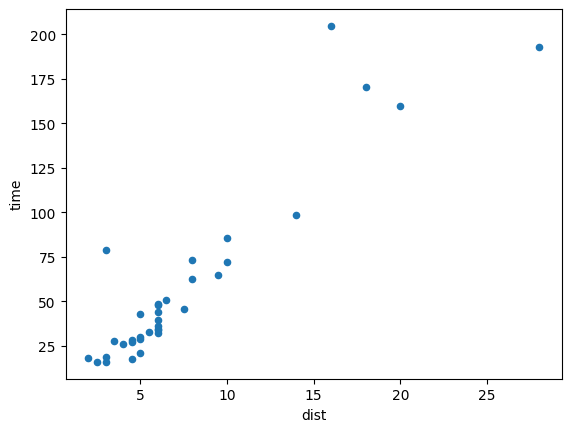

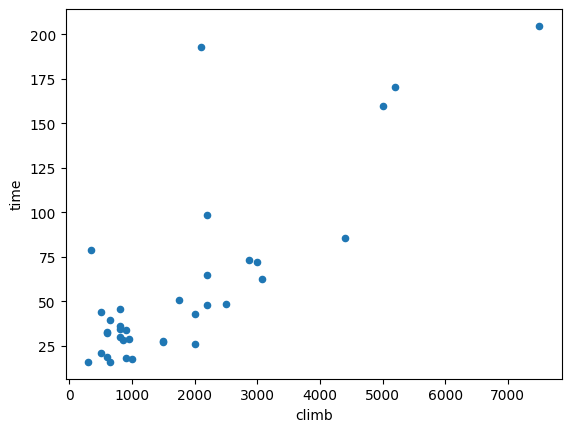

In [11]:
# a) Wykres rozproszenia (wykres punktowy) - sprawdzenie czy występuje liniowa zależność

hills.plot.scatter(x = 'dist', y = 'time')
hills.plot.scatter(x = 'climb', y = 'time')
plt.show()

In [12]:
# b) Wyliczenie współczynnika korelacji Pearsona - badamy czy występuje liniowa zależność
hills[['dist', 'time', 'climb']].corr()

,dist,time,climb
dist,1.000000,0.919589,0.652346
time,0.919589,1.000000,0.805239
climb,0.652346,0.805239,1.000000


#### Budujemy model regresji liniowej dla pary zmiennych dist i time

In [13]:
# Podział zmiennych na y i X
y = hills.time
X = hills.drop(["time", "Unnamed: 0", 'climb'], axis = 1)

# Model regresji liniowej
lm = LinearRegression()
lm = lm.fit(X, y)


In [14]:
# Współczynniki
lm.coef_

array([8.33045619])

In [15]:
# Wyraz wolny
lm.intercept_

-4.840720185065344

-----
##### *Zadanie 6*

Na wykresie rozproszenia dla `dist` i `time` zaznacz wyestymowaną prostą z modelu liniowego.

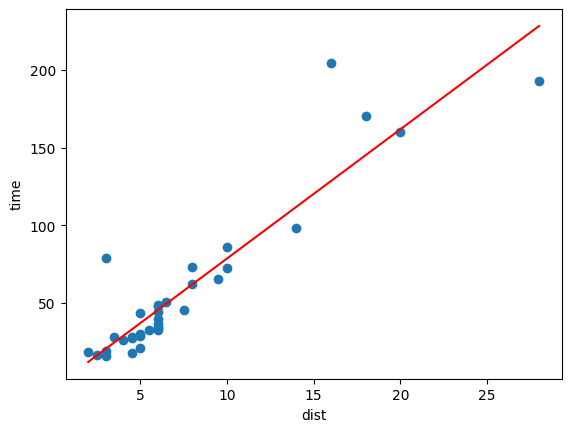

In [16]:
fig, ax = plt.subplots()
ax.scatter(hills.dist, hills.time)
x_grid = np.linspace(hills.dist.min(), hills.dist.max(), 100)
ax.plot(x_grid, lm.predict(pd.DataFrame({'dist': x_grid})), color='red')
ax.set_xlabel('dist')
ax.set_ylabel('time')
plt.show()


-----
##### *Zadanie 7*

Zbuduj model regresji liniowej opisujący zależność *time* od *climb*, wyznacz współczynniki, narysuj wykres rozproszenia i zaznacz wyestymowaną prostą.

In [17]:
# Podział zmiennych na X i y
y = hills.time
X = hills.drop(["time", "Unnamed: 0", 'dist'], axis = 1)

# Dopasowanie modelu regresji liniowej
lm = LinearRegression()
lm = lm.fit(X, y)

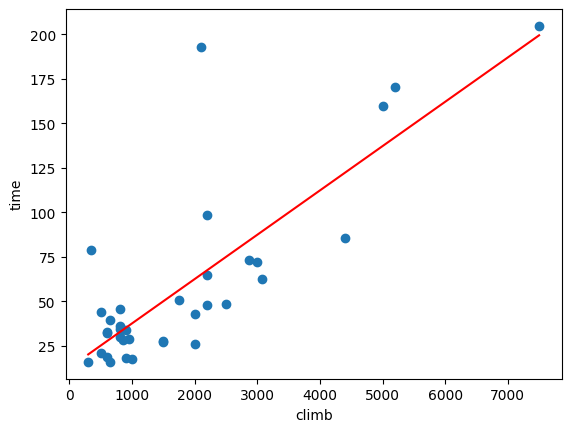

In [18]:
fig, ax = plt.subplots()
ax.scatter(hills.climb, hills.time)
x_grid = np.linspace(hills.climb.min(), hills.climb.max(), 100)
ax.plot(x_grid, lm.predict(pd.DataFrame({'climb': x_grid})), color='red')
ax.set_xlabel('climb')
ax.set_ylabel('time')
plt.show()


### 3. Model regresji logistycznej

W modelu regresji liniowej, predykcja jest ciągłą wartością (np. cena domu, wzrost), a model wygląda następująco:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$
$\hat{y}$ to przewidywana ciągła wartość.

$\beta_i$ to współczynniki (wagi) modelu.

$x_i$ to zmienne niezależne (cechy).

Ponieważ wartości prognozowane przez model regresji liniowej są rzeczywiste (od $-\infty$ do $+\infty$), a naszym celem jest klasyfikacja, stosujemy funkcję logistyczną jako przekształcenie.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
Gdzie $z$ to liniowa: $z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$.

Podstawiając predykcję liniową ($z$) do funkcji logistycznej, otrzymujemy model regresji logistycznej, który zwraca prawdopodobieństwo $P(Y=1|X)$:$$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

W regresji logistycznej istotne jest pojęcie logitu, który jest logarytmem naturalnym ze stosunku szans:$$\text{Logit} = \ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right)$$Zauważ, że logit jest równy liniowej kombinacji cech (wynikowi regresji liniowej):$$\ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$To jest powód, dla którego model nazywa się regresją logistyczną - ponieważ regresja jest wykonywana na logarytmie szans (logits).

-----
##### *Zadanie 8*

Przygotuj zbiór danych `SAheart.data` do dalszej pracy.


In [19]:
SAheart = pd.read_csv("SAheart.data")

In [20]:
# Podział zbioru na train i test; identyfikator nie jest cechą
# Identyfikator nie jest cechą; kodujemy zmienną `famhist` na zmienną binarną
y = SAheart.chd
X = SAheart.drop(['chd', 'row.names'], axis=1)
X["famhist"] = X["famhist"].map({'Present': 1, 'Absent': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)

-----
##### *Zadanie 9*

a) Dopasuj model regresji logistycznej do danych `SAheart.data`.

b) Oblicz prawdopodobieństwa przynależności do klasy 1 dla zbioru testowego.

c) Dokonaj predykcji dla obserwacji o wartościach `sbp = 127`, `age = 30`, `alcohol = 0`, `obesity = 25`, `typea = 49`, `famhist = 'Present'`, `tobacco = 0`, `ldl = 4.44`, `adiposity = 18`.

d) Oceń model na zbiorze testowym za pomocą `accuracy` i ROC AUC.


In [21]:
# Dopasowanie modelu regresji logistycznej
lm = LogisticRegression(C=np.inf, max_iter=300)
lm.fit(X_train, y_train)

LogisticRegression(C=inf, max_iter=300)

In [22]:
# Współczynniki
lm.coef_

array([[-6.07349975e-04,  1.09732345e-01,  1.81786418e-01,
         2.64294987e-02,  6.37886344e-01,  4.64160878e-02,
        -8.64980200e-02,  1.10830692e-03,  5.61841618e-02]])

In [23]:
# Predykcja (prawdopodobieństwa) i ocena modelu na zbiorze testowym.
y_pred = lm.predict(X_test)
y_prob = lm.predict_proba(X_test)[:, 1]
print("Pierwsze prawdopodobieństwa:", np.round(y_prob[:5], 3))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC AUC:", round(roc_auc_score(y_test, y_prob), 3))


Pierwsze prawdopodobieństwa: [0.108 0.139 0.379 0.755 0.48 ]
Accuracy: 0.705
ROC AUC: 0.727


In [24]:
# Nowa obserwacja
new_obs = pd.DataFrame(
    {
        "sbp": [127],
        "tobacco": [0],
        "ldl": [4.44],
        "adiposity": [18],
        "famhist": [1],
        "typea": [49],
        "obesity": [25],
        "alcohol": [0],
        "age": [30],
    }
)

In [25]:
# Predykcja dla nowej obserwacji
lm.predict_proba(new_obs)

array([[0.88524993, 0.11475007]])

### 4. Wprowadzenie do `Pipeline`

W praktyce modelowanie zwykle obejmuje więcej niż samo dopasowanie klasyfikatora: na przykład uzupełnianie braków, kodowanie kategorii albo skalowanie zmiennych. Obiekt `Pipeline` łączy takie kroki w jeden estymator. Dzięki temu podczas `fit` transformacje są dopasowywane wyłącznie do zbioru treningowego, a następnie automatycznie stosowane do nowych danych.

W następnym laboratorium wykorzystamy `Pipeline` do pełnego przygotowania danych o różnych typach i z brakującymi wartościami.


#### Przykład: regresja logistyczna w `Pipeline`

Poniżej łączymy standaryzację i regresję logistyczną w jeden obiekt. Po wywołaniu `fit` skaler jest dopasowywany wyłącznie do danych treningowych, a następnie te same kroki są automatycznie stosowane przy `predict` i `predict_proba`.


In [26]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=np.inf, max_iter=300)),
])
logistic_pipeline.fit(X_train, y_train)

pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("Accuracy pipeline'u na zbiorze testowym:",
      round(logistic_pipeline.score(X_test, y_test), 3))
print("Pierwsze prawdopodobieństwa:", np.round(pipeline_probabilities[:5], 3))


Accuracy pipeline'u na zbiorze testowym: 0.705
Pierwsze prawdopodobieństwa: [0.108 0.138 0.38  0.755 0.48 ]
